In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path(r'C:\Users\asus\Assignment Task 6\Online Retail.xlsx')

df = pd.read_excel(
    DATA_PATH,
    dtype={
        "InvoiceNo": str,
        "StockCode": str,
        "CustomerID": "string"
    }
)

print("Dataset shape:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502,United Kingdom


In [2]:
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), object(1), str(3), string(1)
memory usage: 33.1+ MB

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice      

In [3]:
missing_report = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

cancelled = df["InvoiceNo"].str.startswith("C", na=False)
print("Cancellation rows:", cancelled.sum())

print("Negative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())
print("Non-positive price rows:", (df["UnitPrice"] <= 0).sum())

print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

Exact duplicate rows: 5268
Cancellation rows: 9288
Negative quantity rows: 10624
Zero quantity rows: 0
Non-positive price rows: 2517
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [5]:
# Keep the original dataset unchanged
raw = df.copy()

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Remove cancellation invoices from the positive-sales analysis
is_cancelled = df["InvoiceNo"].str.startswith("C", na=False)

# Keep valid positive sales lines
sales_clean = df.loc[
    (~is_cancelled)
    & df["InvoiceDate"].notna()
    & df["Quantity"].notna()
    & df["UnitPrice"].notna()
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

# Standardize text fields
sales_clean["Description"] = (
    sales_clean["Description"].str.strip()
)
sales_clean["Country"] = sales_clean["Country"].str.strip()

# Calculate transaction-line revenue
sales_clean["Revenue"] = (
    sales_clean["Quantity"] * sales_clean["UnitPrice"]
)

# Create a chronological month field
sales_clean["YearMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

# Create the output directory
output_dir = Path("../data/cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
sales_clean.to_csv(
    output_dir / "Online_Retail_Cleaned.csv",
    index=False
)

# Separate customer-analysis data without missing customer IDs
customer_sales = sales_clean.dropna(
    subset=["CustomerID"]
).copy()

customer_sales.to_csv(
    output_dir / "Online_Retail_Customer_Analysis.csv",
    index=False
)

print("Original rows:", len(raw))
print("Rows after removing exact duplicates:", len(df))
print("Cleaned positive-sales rows:", len(sales_clean))
print("Rows with identified customers:", len(customer_sales))
print("Positive-sales revenue (£):", round(sales_clean["Revenue"].sum(), 2))

Original rows: 541909
Rows after removing exact duplicates: 536641
Cleaned positive-sales rows: 524878
Rows with identified customers: 392692
Positive-sales revenue (£): 10642110.8


In [6]:
print("Missing values:")
print(sales_clean.isna().sum())

print("\nExact duplicates:", sales_clean.duplicated().sum())
print("Cancellation invoices:",
      sales_clean["InvoiceNo"].str.startswith("C", na=False).sum())
print("Invalid quantities:", (sales_clean["Quantity"] <= 0).sum())
print("Invalid prices:", (sales_clean["UnitPrice"] <= 0).sum())

display(sales_clean.head())

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
YearMonth           0
dtype: int64

Exact duplicates: 0
Cancellation invoices: 0
Invalid quantities: 0
Invalid prices: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12


In [8]:
display(
    sales_clean[
        ["Quantity", "UnitPrice", "Revenue"]
    ].describe().round(2)
)

print("Total revenue (£):", round(sales_clean["Revenue"].sum(), 2))
print("Total units:", sales_clean["Quantity"].sum())
print("Unique invoices:", sales_clean["InvoiceNo"].nunique())
print("Unique customers:", sales_clean["CustomerID"].nunique())
print("Unique products:", sales_clean["StockCode"].nunique())
print("Average line revenue (£):", round(sales_clean["Revenue"].mean(), 2))

,Quantity,UnitPrice,Revenue
count,524878.00,524878.00,524878.00
mean,10.62,3.92,20.28
std,156.28,36.09,271.69
min,1.00,0.00,0.00
25%,1.00,1.25,3.90
50%,4.00,2.08,9.92
75%,11.00,4.13,17.70
max,80995.00,13541.33,168469.60


Total revenue (£): 10642110.8
Total units: 5572420
Unique invoices: 19960
Unique customers: 4338
Unique products: 3922
Average line revenue (£): 20.28


In [9]:
monthly_sales = (
    sales_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

display(monthly_sales.round(2))

print("Highest month:", monthly_sales.idxmax())
print("Highest monthly revenue (£):", round(monthly_sales.max(), 2))

print("Lowest month:", monthly_sales.idxmin())
print("Lowest monthly revenue (£):", round(monthly_sales.min(), 2))

YearMonth
2010-12     821452.73
2011-01     689811.61
2011-02     522545.56
2011-03     716215.26
2011-04     536968.49
2011-05     769296.61
2011-06     760547.01
2011-07     718076.12
2011-08     757841.38
2011-09    1056435.19
2011-10    1151263.73
2011-11    1503866.78
2011-12     637790.33
Name: Revenue, dtype: float64

Highest month: 2011-11
Highest monthly revenue (£): 1503866.78
Lowest month: 2011-02
Lowest monthly revenue (£): 522545.56


In [10]:
product_sales = (
    sales_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_sales = (
    sales_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(product_sales.head(10).round(2))
display(country_sales.head(10).round(2))

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Australia          138453.81
Spain               61558.56
Switzerland         57067.60
Belgium             41196.34
Sweden              38367.83
Name: Revenue, dtype: float64

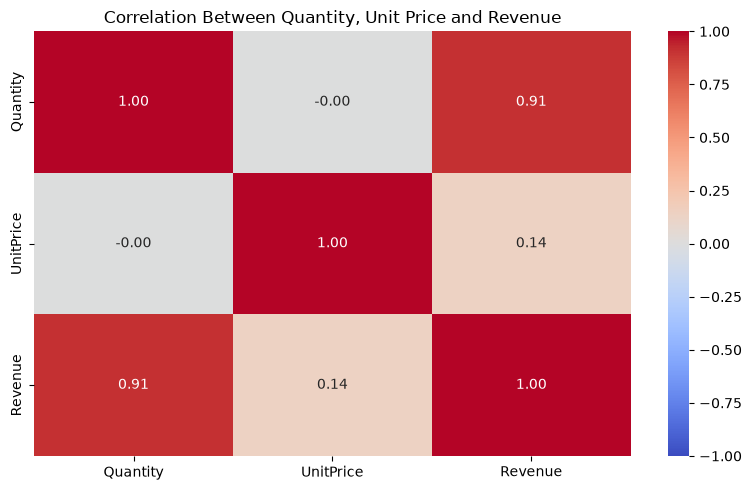

In [11]:
# Create the visualizations folder if it doesn't exist
output_folder = Path("../visualizations")
output_folder.mkdir(parents=True, exist_ok=True)

# Select numeric columns
numeric_data = sales_clean[["Quantity", "UnitPrice", "Revenue"]]

# Calculate correlation
correlation = numeric_data.corr()

# Draw heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Quantity, Unit Price and Revenue")
plt.tight_layout()

# Save the image
plt.savefig(output_folder / "correlation_heatmap.png", dpi=150)
plt.show()

Lower bound: -16.8
Upper bound: 38.4
Potential outlier rows: 42624


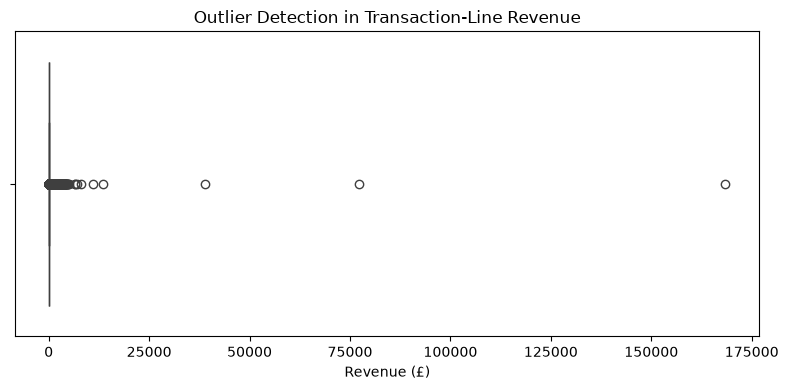

In [12]:
q1 = sales_clean["Revenue"].quantile(0.25)
q3 = sales_clean["Revenue"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = sales_clean[
    (sales_clean["Revenue"] < lower_bound)
    | (sales_clean["Revenue"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outlier rows:", len(outliers))

plt.figure(figsize=(8, 4))
sns.boxplot(x=sales_clean["Revenue"])
plt.title("Outlier Detection in Transaction-Line Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("../visualizations/revenue_outliers.png", dpi=150)
plt.show()

In [13]:
Path("../visualizations").mkdir(parents=True, exist_ok=True)

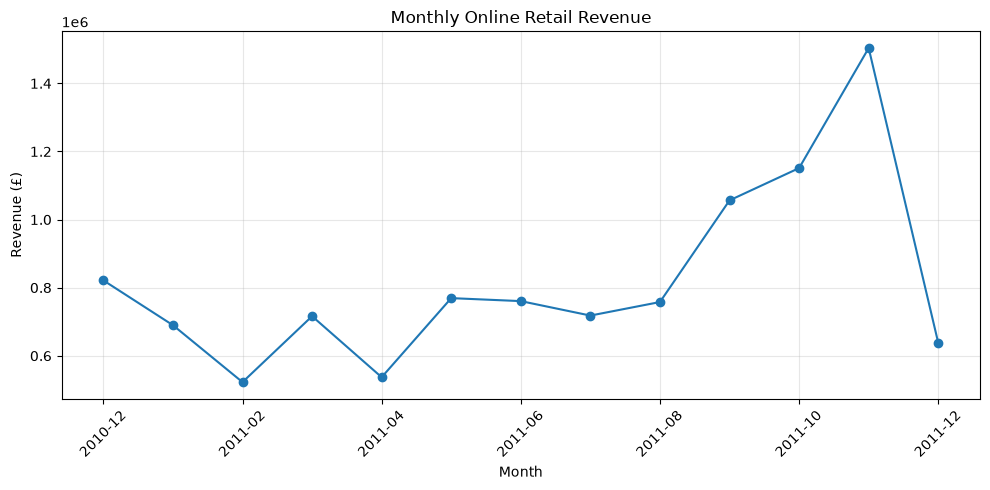

In [14]:
monthly_sales.plot(
    kind="line", marker="o", figsize=(10, 5)
)
plt.title("Monthly Online Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../visualizations/01_monthly_revenue.png", dpi=150)
plt.show()

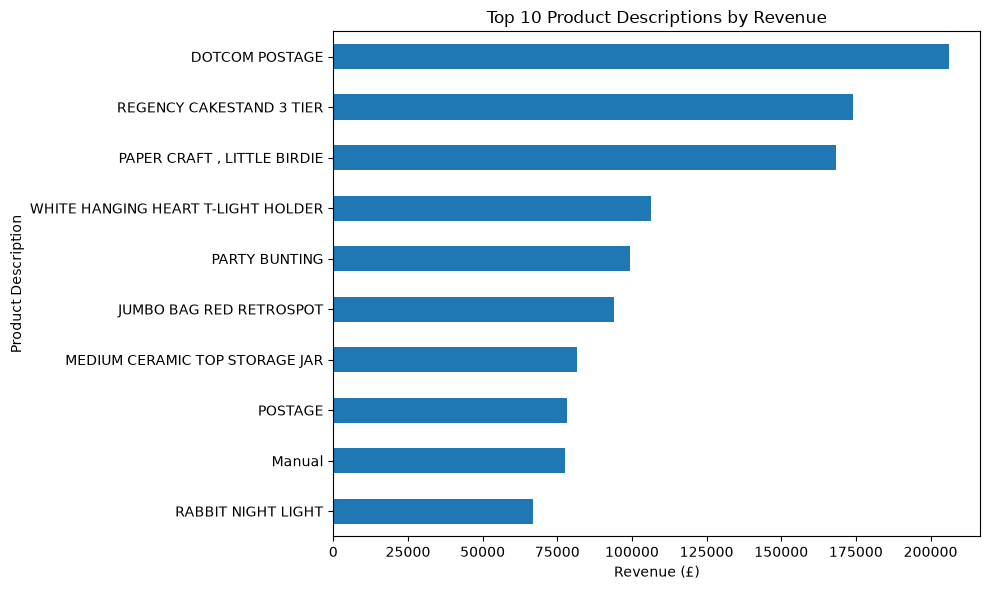

In [22]:
product_sales.head(10).sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Product Descriptions by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product Description")
plt.tight_layout()
plt.savefig("../visualizations/02_top_products.png", dpi=150)
plt.show()

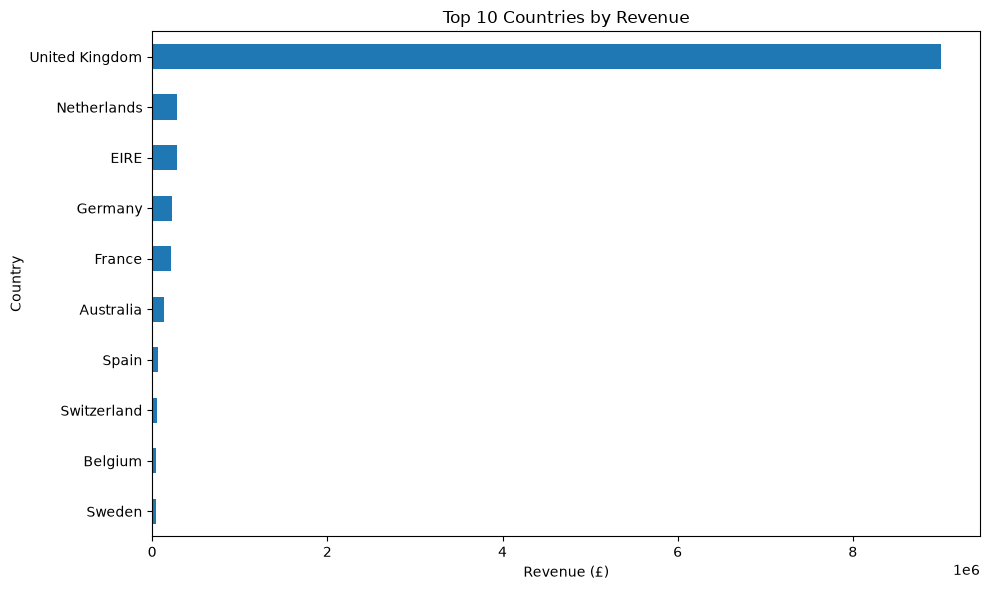

In [15]:
country_sales.head(10).sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("../visualizations/03_country_revenue.png", dpi=150)
plt.show()

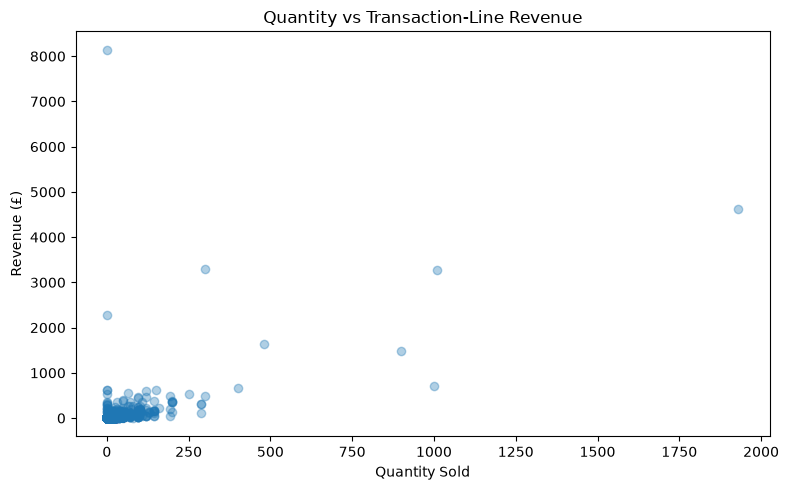

In [16]:
sample = sales_clean.sample(
    min(5000, len(sales_clean)),
    random_state=42
)

plt.figure(figsize=(8, 5))
plt.scatter(
    sample["Quantity"],
    sample["Revenue"],
    alpha=0.35
)
plt.title("Quantity vs Transaction-Line Revenue")
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig("../visualizations/04_quantity_revenue.png", dpi=150)
plt.show()

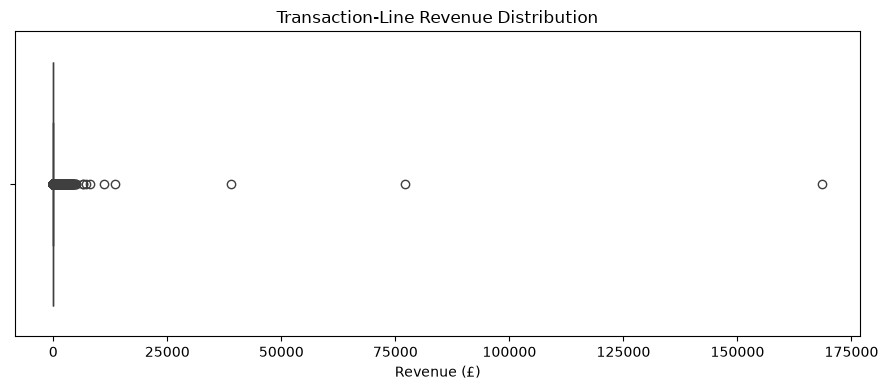

In [17]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=sales_clean["Revenue"])
plt.title("Transaction-Line Revenue Distribution")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.savefig("../visualizations/05_revenue_outliers.png", dpi=150)
plt.show()

In [19]:
df = pd.read_excel(
    DATA_PATH,
    dtype={"InvoiceNo": str, "StockCode": str}
)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df = df.drop_duplicates().copy()

# Exclude cancellations and invalid sales lines
valid_sales = (
    ~df["InvoiceNo"].str.startswith("C", na=False)
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & df["InvoiceDate"].notna()
)

sales_clean = df.loc[valid_sales].copy()

sales_clean["Revenue"] = (
    sales_clean["Quantity"] * sales_clean["UnitPrice"]
)

print("Cleaned rows:", len(sales_clean))
print("Total revenue:", round(sales_clean["Revenue"].sum(), 2))

Cleaned rows: 524878
Total revenue: 10642110.8


In [20]:
from IPython.display import display, HTML

total_revenue = sales_clean["Revenue"].sum()
total_orders = sales_clean["InvoiceNo"].nunique()
unique_customers = sales_clean["CustomerID"].nunique()
total_units = sales_clean["Quantity"].sum()
average_order_value = total_revenue / total_orders if total_orders else 0

kpis = [
    ("Total Revenue", f"£{total_revenue:,.2f}"),
    ("Total Orders", f"{total_orders:,}"),
    ("Unique Customers", f"{unique_customers:,}"),
    ("Units Sold", f"{total_units:,}"),
    ("Average Order Value", f"£{average_order_value:,.2f}")
]

cards_html = """
<div style="display:grid;
grid-template-columns:repeat(auto-fit,minmax(160px,1fr));
gap:12px;">
"""

for title, value in kpis:
    cards_html += f"""
    <div style="border:1px solid #d9dee7;
    border-radius:12px;padding:18px;background:#f8fafc;">
        <div style="font-size:13px;color:#526174;">{title}</div>
        <div style="font-size:23px;font-weight:bold;
        margin-top:10px;color:#147d72;">{value}</div>
    </div>
    """

cards_html += "</div>"

display(HTML(cards_html))

In [21]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

sales_clean["YearMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

countries = ["All Countries"] + sorted(
    sales_clean["Country"].dropna().unique().tolist()
)

country_filter = widgets.Dropdown(
    options=countries,
    value="All Countries",
    description="Country:",
    layout=widgets.Layout(width="350px")
)

date_filter = widgets.SelectionRangeSlider(
    options=sorted(sales_clean["YearMonth"].unique()),
    index=(0, len(sales_clean["YearMonth"].unique()) - 1),
    description="Months:",
    layout=widgets.Layout(width="650px"),
    continuous_update=False
)

output = widgets.Output()

def update_dashboard(change=None):
    with output:
        clear_output(wait=True)

        data = sales_clean.copy()

        if country_filter.value != "All Countries":
            data = data[data["Country"] == country_filter.value]

        start_month, end_month = date_filter.value
        data = data[
            data["YearMonth"].between(start_month, end_month)
        ]

        revenue = data["Revenue"].sum()
        orders = data["InvoiceNo"].nunique()
        customers = data["CustomerID"].nunique()
        units = data["Quantity"].sum()

        display(HTML(f"""
        <h2>Online Retail Sales Dashboard</h2>
        <p><b>Total Revenue:</b> £{revenue:,.2f}
        &nbsp; | &nbsp; <b>Orders:</b> {orders:,}
        &nbsp; | &nbsp; <b>Customers:</b> {customers:,}
        &nbsp; | &nbsp; <b>Units Sold:</b> {units:,}</p>
        """))

        monthly = data.groupby("YearMonth", as_index=False)["Revenue"].sum()

        fig1 = px.line(
            monthly, x="YearMonth", y="Revenue",
            markers=True, title="Monthly Revenue"
        )
        fig1.show()

        products = (
            data.groupby("Description", as_index=False)["Revenue"]
            .sum()
            .sort_values("Revenue", ascending=False)
            .head(10)
        )

        fig2 = px.bar(
            products.sort_values("Revenue"),
            x="Revenue", y="Description",
            orientation="h", title="Top 10 Products by Revenue"
        )
        fig2.show()

        country_sales = (
            data.groupby("Country", as_index=False)["Revenue"]
            .sum()
            .nlargest(10, "Revenue")
        )

        fig3 = px.bar(
            country_sales.sort_values("Revenue"),
            x="Revenue", y="Country",
            orientation="h", title="Top 10 Countries by Revenue"
        )
        fig3.show()

country_filter.observe(update_dashboard, names="value")
date_filter.observe(update_dashboard, names="value")

display(widgets.VBox([
    country_filter,
    date_filter,
    output
]))

update_dashboard()

In [22]:
# Insight 1: Best-performing month
print("Monthly revenue:")
display(monthly_sales.sort_values(ascending=False).head(5).round(2))

# Insight 2: Highest-revenue countries
print("Country revenue:")
display(country_sales.head(5).round(2))

# Insight 3: Highest-revenue product descriptions
print("Product revenue:")
display(product_sales.head(5).round(2))

# Insight 4: Repeat customers
identified = sales_clean.dropna(subset=["CustomerID"])

orders_per_customer = (
    identified.groupby("CustomerID")["InvoiceNo"].nunique()
)

repeat_customers = (orders_per_customer > 1).sum()
total_customers = orders_per_customer.size

print("Identified customers:", total_customers)
print("Repeat customers:", repeat_customers)
print(
    "Repeat customer percentage:",
    round(repeat_customers / total_customers * 100, 2), "%"
)

# Insight 5: Missing customer identification
print(
    "Sales lines without CustomerID:",
    sales_clean["CustomerID"].isna().sum()
)

Monthly revenue:


YearMonth
2011-11    1503866.78
2011-10    1151263.73
2011-09    1056435.19
2010-12     821452.73
2011-05     769296.61
Name: Revenue, dtype: float64

Country revenue:


Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Name: Revenue, dtype: float64

Product revenue:


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
Name: Revenue, dtype: float64

Identified customers: 4338
Repeat customers: 2845
Repeat customer percentage: 65.58 %
Sales lines without CustomerID: 132186
